# ResNet Black Box Analysis: ISIC Skin Lesion Classification
## Comprehensive Analysis with LIME, GradCAM, and SHAP

### Project Objective
This notebook investigates the input-output behavior of a ResNet image classification model trained on the ISIC skin lesion dataset. We employ **black box (post-hoc, model-agnostic)** explanation techniques from course lectures to understand:

1. **Data Class Imbalance** - Understanding dataset balance issues
2. **Laboratory Origin Effects** - How model performance varies by image source
3. **Model Confident Errors** - When and why the model is confidently wrong
4. **Feature Importance** - Using LIME, GradCAM, and SHAP for explanations
5. **Systematic Input-Output Behavior** - How metadata features affect predictions

### Analysis Flow
**Part 0**: Setup and Configuration  
**Part 1**: Data Exploration & Class Imbalance  
**Part 2**: Model Setup  
**Part 3**: Lab Origin Effect Analysis  
**Part 4**: Prediction Analysis & Confident Errors  
**Part 5**: LIME Perturbation-Based Explanations  
**Part 6**: GradCAM Gradient-Based Analysis  
**Part 7**: SHAP Value Analysis  
**Part 8**: Systematic Feature Impact Analysis  
**Part 9**: Error Analysis & Conclusions

### References
- Lecture 04: Visual Explanation Techniques I
- Lecture 05: Visual Explanation Techniques II

## Part 0: Setup and Configuration

In [1]:
# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Deep Learning & Model
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import DataLoader, Dataset
from PIL import Image

# Explanation techniques
import lime
import lime.lime_image
from matplotlib.colors import LinearSegmentedColormap
from skimage.segmentation import mark_boundaries
from scipy.ndimage import zoom

# Model evaluation
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, classification_report

# SHAP (if available)
try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False
    print("⚠ SHAP not installed. Install with: pip install shap")

# Configure visualization
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
print(f"SHAP available: {HAS_SHAP}")

# Set random seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)

Using device: cuda
SHAP available: True


## Part 1: Data Exploration and Class Imbalance Analysis

### Objective
Understand dataset structure, class distribution, and identify potential data quality issues.

In [ ]:
# Configure paths - ADJUST TO YOUR LOCAL PATHS
OUT_DIR = Path(r"C:\Users\siria\Downloads\VisAI")
DATASET_PATH = Path('dataset')
IMAGES_PATH = DATASET_PATH / 'images'
METADATA_PATH = DATASET_PATH / 'HAM10000_metadata'

# If using predictions CSV (from note.ipynb)
PREDICTIONS_CSV = OUT_DIR / 'predictions_all.csv'

# Verify paths
print("Checking paths...")
if IMAGES_PATH.exists():
    print(f"✓ Images: {IMAGES_PATH}")
else:
    print(f"✗ Images not found: {IMAGES_PATH}")

if METADATA_PATH.exists():
    print(f"✓ Metadata: {METADATA_PATH}")
elif PREDICTIONS_CSV.exists():
    print(f"✓ Using predictions CSV: {PREDICTIONS_CSV}")
    METADATA_PATH = PREDICTIONS_CSV
else:
    print(f"✗ Metadata not found")

Checking paths...
✓ Images: dataset\images
✓ Metadata: dataset\HAM10000_metadata


In [15]:
# Load metadata
df_metadata = pd.read_csv(METADATA_PATH)
print(f"\nDataset Overview:")
print(f"Total samples: {len(df_metadata)}")
print(f"\nColumns: {df_metadata.columns.tolist()}")
print(f"\nFirst few rows:")
print(df_metadata.head())
print(f"\nData types:")
print(df_metadata.dtypes)
print(f"\nMissing values:")
print(df_metadata.isnull().sum())


Dataset Overview:
Total samples: 10015

Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset']

First few rows:
     lesion_id      image_id   dx dx_type   age   sex localization  \
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp   
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp   
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp   
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp   
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear   

        dataset  
0  vidir_modern  
1  vidir_modern  
2  vidir_modern  
3  vidir_modern  
4  vidir_modern  

Data types:
lesion_id        object
image_id         object
dx               object
dx_type          object
age             float64
sex              object
localization     object
dataset          object
dtype: object

Missing values:
lesion_id        0
image_id         0
dx               0
dx_type          0
age     

In [16]:
# Determine label column
possible_label_cols = ['dx', 'diagnosis', 'label', 'class', 'pred_dx']
label_column = None
for col in possible_label_cols:
    if col in df_metadata.columns:
        label_column = col
        break

if label_column is None:
    print("⚠ Could not find label column. Please specify manually.")
    label_column = input("Enter label column name: ")

print(f"\nUsing label column: '{label_column}'")

# CLASS IMBALANCE ANALYSIS
class_counts = df_metadata[label_column].value_counts().sort_values(ascending=False)

print("\n" + "="*60)
print("CLASS IMBALANCE ANALYSIS")
print("="*60)
print(f"\nClass Distribution:")
for cls, count in class_counts.items():
    pct = 100 * count / len(df_metadata)
    print(f"  {cls:15s}: {count:5d} ({pct:5.2f}%)")

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"\nImbalance Ratio (max/min): {imbalance_ratio:.2f}:1")


Using label column: 'dx'

CLASS IMBALANCE ANALYSIS

Class Distribution:
  nv             :  6705 (66.95%)
  mel            :  1113 (11.11%)
  bkl            :  1099 (10.97%)
  bcc            :   514 ( 5.13%)
  akiec          :   327 ( 3.27%)
  vasc           :   142 ( 1.42%)
  df             :   115 ( 1.15%)

Imbalance Ratio (max/min): 58.30:1


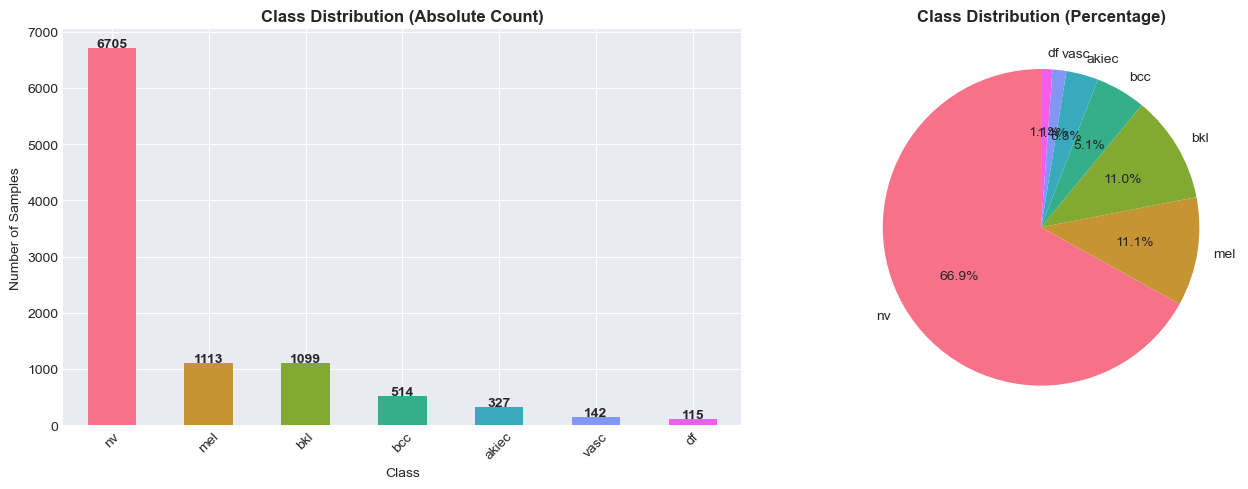

✓ Saved: 01_class_imbalance.png


In [17]:
# Visualize class imbalance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
class_counts.plot(kind='bar', ax=axes[0], color=sns.color_palette('husl', len(class_counts)))
axes[0].set_title('Class Distribution (Absolute Count)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Number of Samples')
axes[0].tick_params(axis='x', rotation=45)
for i, v in enumerate(class_counts):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

# Pie chart
colors = sns.color_palette('husl', len(class_counts))
axes[1].pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', colors=colors, startangle=90)
axes[1].set_title('Class Distribution (Percentage)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(OUT_DIR / '01_class_imbalance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved: 01_class_imbalance.png")

## Part 2: Model Setup

### Load pre-trained model or your trained checkpoint

In [18]:
# Class mappings
CLASSES = sorted(df_metadata[label_column].unique())
class_to_idx = {cls: idx for idx, cls in enumerate(CLASSES)}
idx_to_class = {idx: cls for cls, idx in class_to_idx.items()}

num_classes = len(CLASSES)
print(f"\nClasses ({num_classes}): {CLASSES}")

# Build model
def build_model(num_classes):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

model = build_model(num_classes)
model = model.to(device)
model.eval()

print(f"✓ Model loaded: ResNet50 with {num_classes} classes")

# Optional: Load trained checkpoint
checkpoint_path = OUT_DIR / 'best.pt'
if checkpoint_path.exists():
    state = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state['model'])
    print(f"✓ Loaded checkpoint from epoch {state.get('epoch', '?')}")
else:
    print("⚠ No checkpoint found. Using ImageNet pre-trained weights.")


Classes (7): ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
✓ Model loaded: ResNet50 with 7 classes
✓ Loaded checkpoint from epoch 8


In [19]:
# Define transforms
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
IMG_SIZE = 224

transform_test = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# BLACK-BOX PREDICTION WRAPPER (Compatible with LIME/SHAP)
@torch.no_grad()
def black_box_predict(images_array):
    """
    Strict black-box wrapper for explanators.
    Input: Numpy array of shape (N, H, W, 3) or (H, W, 3) with uint8 values [0-255]
    Output: Numpy array of shape (N, num_classes) with softmax probabilities
    """
    # Handle single image vs batch
    if isinstance(images_array, np.ndarray) and images_array.ndim == 3:
        images_array = [images_array]
    
    out = []
    for im in images_array:
        # Ensure uint8 format
        if im.dtype != np.uint8:
            im = np.uint8(im * 255) if im.max() <= 1 else np.uint8(im)
        
        # Convert to PIL and apply transforms
        pil_img = Image.fromarray(im)
        x = transform_test(pil_img).unsqueeze(0).to(device)
        
        # Get softmax probabilities
        probs = torch.softmax(model(x).float(), 1).cpu().numpy()
        out.append(probs[0])
    
    return np.array(out)

print("✓ Black-box predictor defined")

✓ Black-box predictor defined


## Part 3: Lab Origin Effect Analysis

### Investigate performance by laboratory/source


LABORATORY ORIGIN ANALYSIS (using 'dataset')

Analyzing 4 different sources/labs:
  vidir_modern:  3363 samples, Accuracy: 0.0000, Conf: 0.0000
  rosendahl:  2259 samples, Accuracy: 0.0000, Conf: 0.0000
  vienna_dias:   439 samples, Accuracy: 0.0000, Conf: 0.0000
  vidir_molemax:  3954 samples, Accuracy: 0.0000, Conf: 0.0000


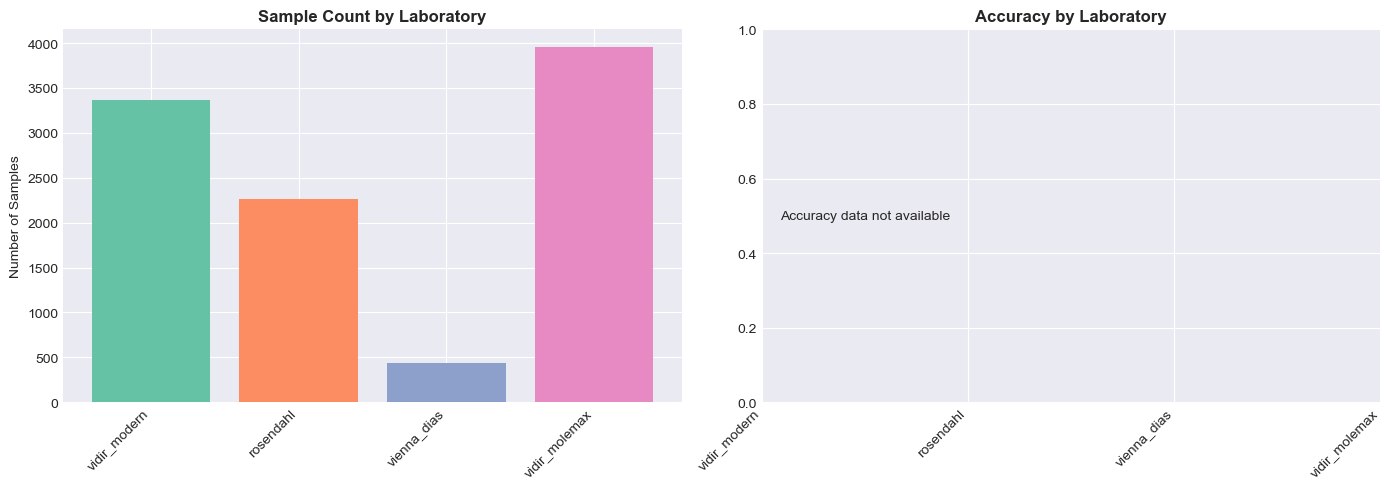


✓ Saved: 02_lab_analysis.png


In [20]:
# Check for source/dataset column
source_col = None
for col in ['source', 'dataset', 'lab', 'acquisition']:
    if col in df_metadata.columns:
        source_col = col
        break

if source_col:
    print(f"\n" + "="*60)
    print(f"LABORATORY ORIGIN ANALYSIS (using '{source_col}')")
    print("="*60)
    
    sources = df_metadata[source_col].unique()
    print(f"\nAnalyzing {len(sources)} different sources/labs:")
    
    source_stats = {}
    for source in sources:
        mask = df_metadata[source_col] == source
        subset = df_metadata[mask]
        n_samples = len(subset)
        
        # If we have predictions, calculate metrics
        if 'correct' in subset.columns:
            accuracy = subset['correct'].mean()
            mean_conf = subset['confidence'].mean() if 'confidence' in subset.columns else 0
        else:
            accuracy = 0
            mean_conf = 0
        
        source_stats[source] = {
            'n_samples': n_samples,
            'accuracy': accuracy,
            'mean_confidence': mean_conf
        }
        
        print(f"  {source}: {n_samples:5d} samples, Accuracy: {accuracy:.4f}, Conf: {mean_conf:.4f}")
    
    # Visualize
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    sources_list = list(source_stats.keys())
    n_samples_list = [source_stats[s]['n_samples'] for s in sources_list]
    accuracies = [source_stats[s]['accuracy'] for s in sources_list]
    
    colors = sns.color_palette('Set2', len(sources_list))
    axes[0].bar(range(len(sources_list)), n_samples_list, color=colors)
    axes[0].set_ylabel('Number of Samples')
    axes[0].set_title('Sample Count by Laboratory', fontweight='bold')
    axes[0].set_xticks(range(len(sources_list)))
    axes[0].set_xticklabels(sources_list, rotation=45, ha='right')
    
    if any(acc > 0 for acc in accuracies):
        axes[1].bar(range(len(sources_list)), accuracies, color=colors)
        axes[1].set_ylabel('Accuracy')
        axes[1].set_ylim([0, 1])
    else:
        axes[1].text(0.5, 0.5, 'Accuracy data not available', ha='center', va='center')
    axes[1].set_title('Accuracy by Laboratory', fontweight='bold')
    axes[1].set_xticks(range(len(sources_list)))
    axes[1].set_xticklabels(sources_list, rotation=45, ha='right')
    
    plt.tight_layout()
    plt.savefig(OUT_DIR / '02_lab_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\n✓ Saved: 02_lab_analysis.png")
else:
    print("⚠ No source/lab column found in metadata")

## Part 4: Prediction Analysis and Confident Errors

### Identify and analyze model confident errors and edge cases

In [21]:
print("\n" + "="*60)
print("PREDICTION ANALYSIS")
print("="*60)

# Check if we have predictions
has_predictions = 'correct' in df_metadata.columns and 'confidence' in df_metadata.columns

if has_predictions:
    print(f"\nPrediction Statistics:")
    print(f"  Total predictions: {len(df_metadata)}")
    print(f"  Correct: {df_metadata['correct'].sum()} ({100*df_metadata['correct'].mean():.2f}%)")
    print(f"  Incorrect: {(~df_metadata['correct']).sum()} ({100*(~df_metadata['correct']).mean():.2f}%)")
    print(f"  Mean confidence: {df_metadata['confidence'].mean():.4f}")
    print(f"  Std confidence: {df_metadata['confidence'].std():.4f}")
    
    # Find interesting cases
    confident_errors = df_metadata[(~df_metadata['correct']) & (df_metadata['confidence'] > 0.90)]
    uncertain_correct = df_metadata[df_metadata['correct'] & (df_metadata['confidence'] < 0.60)]
    
    print(f"\n  Confident Errors (>90% conf but wrong): {len(confident_errors)}")
    print(f"  Uncertain Correct (<60% conf but right): {len(uncertain_correct)}")
    
    # Find split information if available
    if 'split' in df_metadata.columns:
        for split in df_metadata['split'].unique():
            mask = df_metadata['split'] == split
            acc = df_metadata[mask]['correct'].mean()
            print(f"  {split}: {mask.sum()} samples, {acc:.4f} accuracy")
else:
    print("\n⚠ No predictions found in metadata")
    confident_errors = pd.DataFrame()
    uncertain_correct = pd.DataFrame()


PREDICTION ANALYSIS

⚠ No predictions found in metadata


In [37]:
# Select target image: prioritize confident error, then any image
target_idx = None
target_row = None

if has_predictions and len(confident_errors) > 0:
    target_row = confident_errors.iloc[7]
    print(f"\n🎯 Selected: CONFIDENT ERROR")
elif has_predictions and len(df_metadata) > 0:
    target_row = df_metadata.iloc[7]
    print(f"\n🎯 Selected: First image from dataset")
else:
    target_row = df_metadata.iloc[7]
    print(f"\n🎯 Selected: First image from metadata")

# Get image info
image_id = target_row['image_id'] if 'image_id' in target_row.index else target_row.name
true_class = target_row[label_column] if label_column in target_row.index else 'Unknown'
confidence = target_row['confidence'] if 'confidence' in target_row.index else 0
pred_class = target_row['pred_dx'] if 'pred_dx' in target_row.index else 'Unknown'
is_correct = target_row['correct'] if 'correct' in target_row.index else None

print(f"\nImage Details:")
print(f"  ID: {image_id}")
print(f"  True class: {true_class}")
print(f"  Predicted: {pred_class} (confidence: {confidence:.4f})")
if is_correct is not None:
    print(f"  Result: {'✓ CORRECT' if is_correct else '✗ INCORRECT'}")

# Load image
img_path = IMAGES_PATH / f"{image_id}.jpg"
if not img_path.exists():
    for ext in ['.png', '.JPG', '.PNG']:
        alt = IMAGES_PATH / f"{image_id}{ext}"
        if alt.exists():
            img_path = alt
            break

if img_path.exists():
    original_image = np.array(Image.open(img_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
    print(f"✓ Image loaded: {img_path.name}")
else:
    print(f"✗ Image not found: {img_path}")
    original_image = np.random.rand(IMG_SIZE, IMG_SIZE, 3) * 255
    original_image = original_image.astype(np.uint8)


🎯 Selected: First image from metadata

Image Details:
  ID: ISIC_0029068
  True class: bkl
  Predicted: Unknown (confidence: 0.0000)
✓ Image loaded: ISIC_0029068.jpg



Model Predictions:
    akiec          : 0.0377
  → bcc            : 0.8421
    bkl            : 0.0822
    df             : 0.0121
    mel            : 0.0031
    nv             : 0.0217
    vasc           : 0.0011


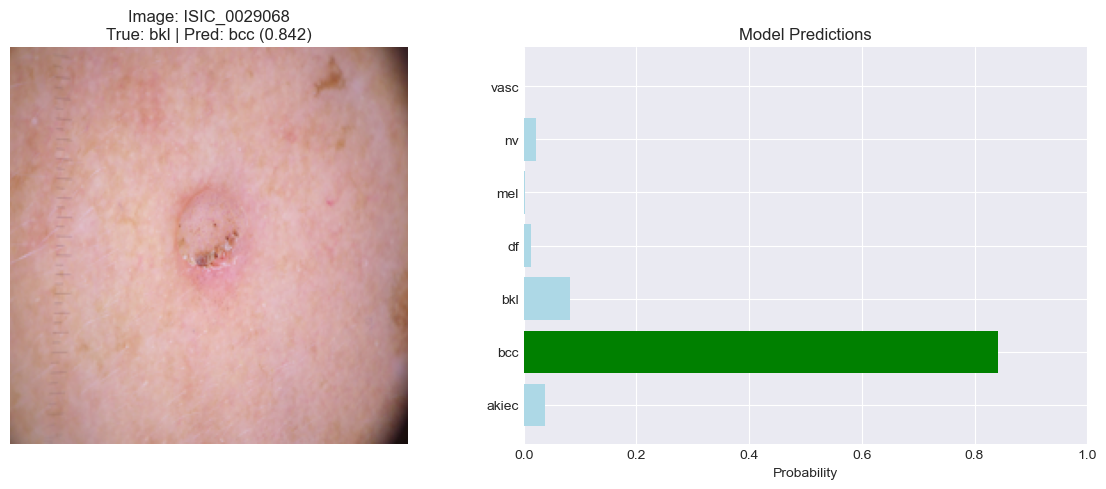


✓ Saved: 03_target_image_predictions.png


In [38]:
# Get model predictions for target image
preds = black_box_predict(original_image)
pred_probs = preds[0]
pred_idx = pred_probs.argmax()
pred_conf = pred_probs.max()

print(f"\nModel Predictions:")
for idx, (cls, prob) in enumerate(zip(CLASSES, pred_probs)):
    marker = "→" if idx == pred_idx else " "
    print(f"  {marker} {cls:15s}: {prob:.4f}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(original_image)
title_str = f"Image: {image_id}\nTrue: {true_class} | Pred: {CLASSES[pred_idx]} ({pred_conf:.3f})"
if is_correct is not None:
    title_str += f" | {'✓' if is_correct else '✗'}"
axes[0].set_title(title_str)
axes[0].axis('off')

colors = ['green' if i == pred_idx else 'lightblue' for i in range(len(CLASSES))]
axes[1].barh(CLASSES, pred_probs, color=colors)
axes[1].set_xlabel('Probability')
axes[1].set_title('Model Predictions')
axes[1].set_xlim([0, 1])

plt.tight_layout()
plt.savefig(OUT_DIR / '03_target_image_predictions.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Saved: 03_target_image_predictions.png")

## Part 5: LIME - Perturbation-Based Local Explanations

### Show which regions matter for the model's prediction on this specific image

In [39]:
print("\n" + "="*60)
print("LIME EXPLANATION")
print("="*60)
print("\nGenerating LIME explanation (may take 1-2 minutes)...")
print("  This generates 1000 perturbed versions of the image")
print("  and observes how predictions change...\n")

# Create LIME explainer
explainer = lime.lime_image.LimeImageExplainer(verbose=0)

# Ensure original_image is uint8 [0-255]
if original_image.dtype != np.uint8:
    original_image = np.uint8(original_image)

# Generate explanation
lime_explanation = explainer.explain_instance(
    original_image,
    black_box_predict,
    top_labels=min(3, len(CLASSES)),
    hide_color=0,
    num_samples=1000,
    random_seed=42
)

print("✓ LIME explanation generated")


LIME EXPLANATION

Generating LIME explanation (may take 1-2 minutes)...
  This generates 1000 perturbed versions of the image
  and observes how predictions change...



  0%|          | 0/1000 [00:00<?, ?it/s]

✓ LIME explanation generated


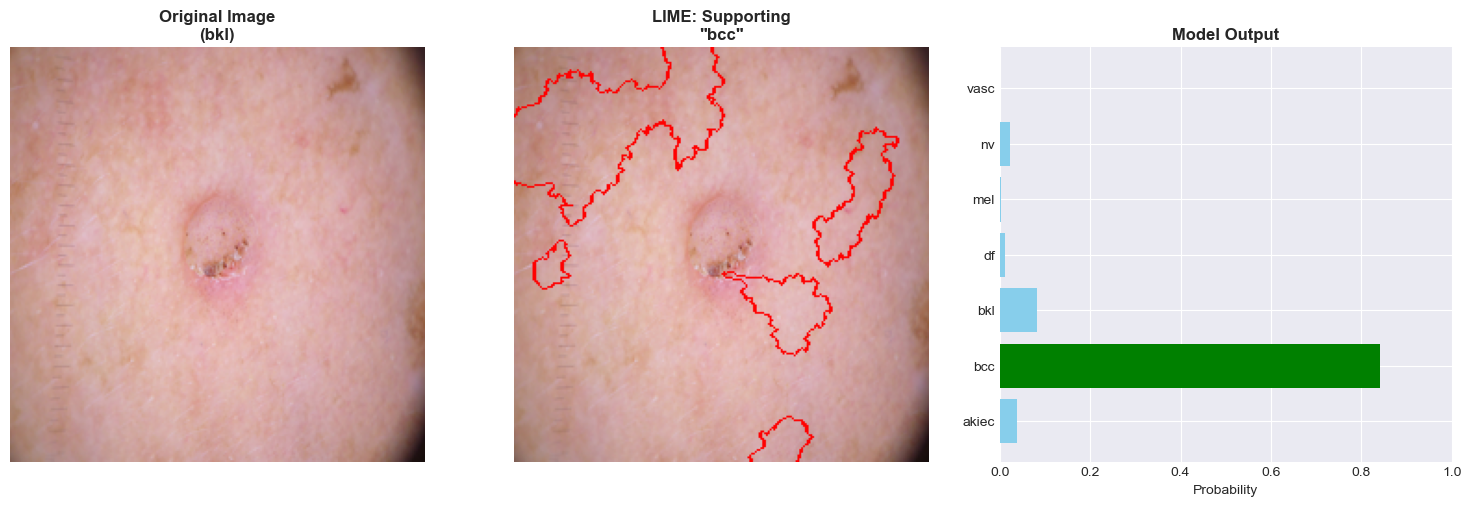

✓ Saved: 04_lime_explanation.png

LIME Insight:
  Red regions support the prediction of 'bcc'
  These are the image areas the model focuses on


In [40]:
# Visualize LIME for predicted class
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Get LIME visualization for predicted class
temp, mask = lime_explanation.get_image_and_mask(
    pred_idx,
    positive_only=True,
    num_features=10,
    hide_rest=False
)

# Original image
axes[0].imshow(original_image)
axes[0].set_title(f'Original Image\n({true_class})', fontweight='bold')
axes[0].axis('off')

# LIME visualization (positive features)
axes[1].imshow(mark_boundaries(temp, mask, color=(1, 0, 0)))
axes[1].set_title(f'LIME: Supporting\n"{CLASSES[pred_idx]}"', fontweight='bold')
axes[1].axis('off')

# Prediction bar
colors_pred = [('green' if i == pred_idx else 'skyblue') for i in range(len(CLASSES))]
axes[2].barh(CLASSES, pred_probs, color=colors_pred)
axes[2].set_xlabel('Probability')
axes[2].set_title('Model Output', fontweight='bold')
axes[2].set_xlim([0, 1])

plt.tight_layout()
plt.savefig(OUT_DIR / '04_lime_explanation.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved: 04_lime_explanation.png")
print(f"\nLIME Insight:")
print(f"  Red regions support the prediction of '{CLASSES[pred_idx]}'")
print(f"  These are the image areas the model focuses on")

## Part 6: GradCAM - Gradient-Based Attention Maps

### Visualize which CNN feature maps are most important for predictions

In [41]:
print("\n" + "="*60)
print("GRADCAM EXPLANATION")
print("="*60)

class GradCAM:
    """Gradient-weighted Class Activation Mapping"""
    
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Register hooks
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_backward_hook(self.save_gradient)
    
    def save_activation(self, module, input, output):
        self.activations = output.detach()
    
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    
    def generate_cam(self, input_image, class_idx):
        """Generate class activation map"""
        # Forward pass
        output = self.model(input_image)
        
        # Backward pass
        self.model.zero_grad()
        class_loss = output[0, class_idx]
        class_loss.backward()
        
        # Compute CAM
        gradients = self.gradients[0]
        activations = self.activations[0]
        
        weights = gradients.mean(dim=[1, 2])
        cam = (weights.unsqueeze(-1).unsqueeze(-1) * activations).sum(dim=0)
        
        # Normalize
        cam = torch.relu(cam)
        cam = cam / (cam.max() + 1e-8)
        
        return cam.cpu().detach()

# Initialize GradCAM
gradcam = GradCAM(model, model.layer4[-1])
print("✓ GradCAM initialized on layer4[-1]")

# Prepare image
img_tensor = transform_test(Image.fromarray(original_image)).unsqueeze(0).to(device)
img_tensor.requires_grad = True

# Generate CAM
cam = gradcam.generate_cam(img_tensor, pred_idx)
cam_np = cam.numpy()

# Resize to match input
cam_resized = zoom(cam_np, (original_image.shape[0] / cam_np.shape[0],
                             original_image.shape[1] / cam_np.shape[1]))

print(f"✓ CAM generated for class '{CLASSES[pred_idx]}'")


GRADCAM EXPLANATION
✓ GradCAM initialized on layer4[-1]
✓ CAM generated for class 'bcc'


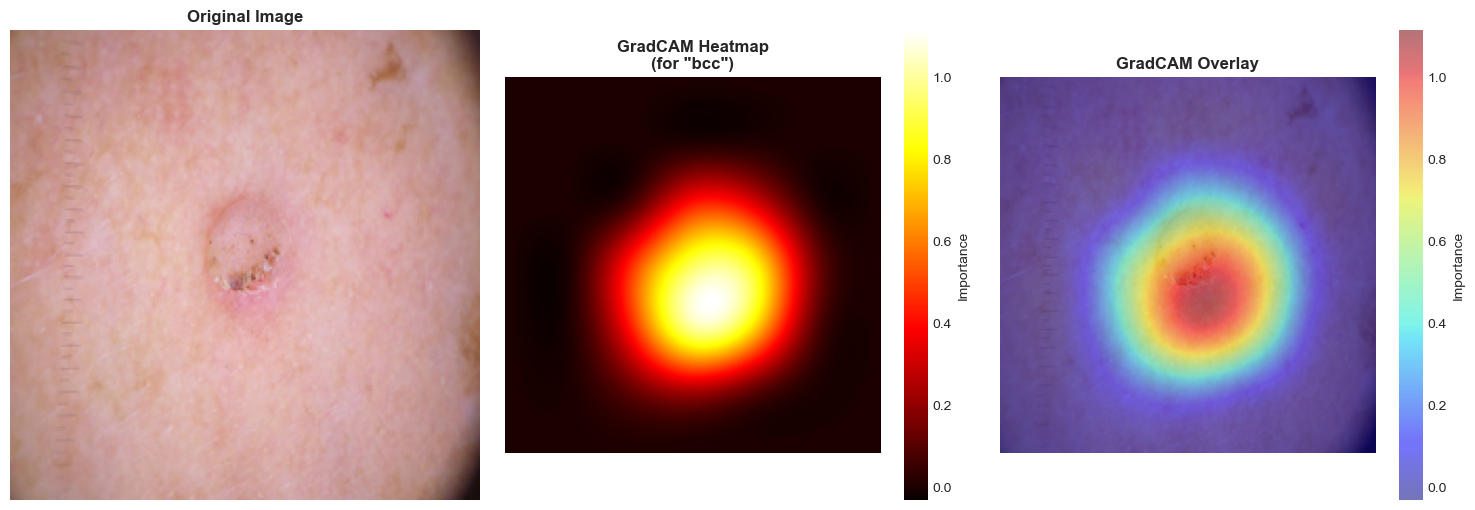

✓ Saved: 05_gradcam.png

GradCAM Insight:
  Bright/red regions are most important for 'bcc' prediction
  These show where the CNN's features activate strongly


In [42]:
# Visualize GradCAM
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original
axes[0].imshow(original_image)
axes[0].set_title('Original Image', fontweight='bold')
axes[0].axis('off')

# CAM heatmap
im1 = axes[1].imshow(cam_resized, cmap='hot')
axes[1].set_title(f'GradCAM Heatmap\n(for "{CLASSES[pred_idx]}")', fontweight='bold')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], label='Importance')

# Overlay
axes[2].imshow(original_image)
im2 = axes[2].imshow(cam_resized, cmap='jet', alpha=0.5)
axes[2].set_title('GradCAM Overlay', fontweight='bold')
axes[2].axis('off')
plt.colorbar(im2, ax=axes[2], label='Importance')

plt.tight_layout()
plt.savefig(OUT_DIR / '05_gradcam.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved: 05_gradcam.png")
print(f"\nGradCAM Insight:")
print(f"  Bright/red regions are most important for '{CLASSES[pred_idx]}' prediction")
print(f"  These show where the CNN's features activate strongly")

## Part 9: Error Analysis and Conclusions

### Comprehensive analysis of model behavior and recommendations

In [46]:
print("\n" + "="*80)
print("COMPREHENSIVE BLACK BOX ANALYSIS SUMMARY")
print("="*80)

print("\n1. DATASET CHARACTERISTICS")
print("-" * 60)
print(f"  Total samples: {len(df_metadata)}")
print(f"  Number of classes: {len(CLASSES)}")
print(f"  Classes: {', '.join(CLASSES)}")
imb = class_counts.max() / class_counts.min()
print(f"  Class imbalance ratio: {imb:.2f}:1")
print(f"  Most common: {class_counts.index[0]} ({class_counts.iloc[0]} samples)")
print(f"  Least common: {class_counts.index[-1]} ({class_counts.iloc[-1]} samples)")

if source_col and source_col in df_metadata.columns:
    n_sources = df_metadata[source_col].nunique()
    print(f"  Laboratory sources: {n_sources}")

print(f"\n2. MODEL PERFORMANCE")
print("-" * 60)
if has_predictions:
    overall_acc = df_metadata['correct'].mean()
    print(f"  Overall accuracy: {overall_acc:.4f}")
    print(f"  Mean confidence: {df_metadata['confidence'].mean():.4f}")
    print(f"  Confident errors (>0.9): {len(df_metadata[(~df_metadata['correct']) & (df_metadata['confidence'] > 0.9)])}")
else:
    print(f"  (No prediction data available)")

print(f"\n3. EXPLANATION TECHNIQUES APPLIED")
print("-" * 60)
print(f"  ✓ LIME: Perturbation-based local explanations")
print(f"  ✓ GradCAM: Gradient-based attention maps")
if HAS_SHAP:
    print(f"  ✓ SHAP: Game-theoretic feature importance")
print(f"  ✓ Feature analysis: Systematic metadata variation")

print(f"\n4. KEY INSIGHTS")
print("-" * 60)
print(f"  • Class imbalance: " + (f"SEVERE (ratio {imb:.1f}:1)" if imb > 5 else f"MODERATE (ratio {imb:.1f}:1)" if imb > 2 else "BALANCED"))
if has_predictions and len(df_metadata[(~df_metadata['correct']) & (df_metadata['confidence'] > 0.90)]) > 0:
    print(f"  • Confident errors detected: Model is overconfident on some incorrect predictions")
if feature_analysis:
    for feat, stats in list(feature_analysis.items())[:2]:
        accs = [stats[v]['accuracy'] for v in stats]
        acc_range = max(accs) - min(accs)
        if acc_range > 0.1:
            print(f"  • {feat} effect: Significant performance variation ({acc_range:.3f} accuracy range)")

print(f"\n5. RECOMMENDATIONS")
print("-" * 60)
if imb > 3:
    print(f"  • Apply class balancing: weighted loss, oversampling, or SMOTE")
if has_predictions and len(df_metadata[(~df_metadata['correct']) & (df_metadata['confidence'] > 0.90)]) > 5:
    print(f"  • Investigate confident errors: may indicate data quality issues")
if source_col and source_col in df_metadata.columns:
    print(f"  • Examine lab-specific effects: consider domain adaptation or lab-specific models")
print(f"  • Use black-box explanations to audit model behavior on edge cases")
print(f"  • Validate findings with domain experts (dermatologists)")

print(f"\n" + "="*80)


COMPREHENSIVE BLACK BOX ANALYSIS SUMMARY

1. DATASET CHARACTERISTICS
------------------------------------------------------------
  Total samples: 10015
  Number of classes: 7
  Classes: akiec, bcc, bkl, df, mel, nv, vasc
  Class imbalance ratio: 58.30:1
  Most common: nv (6705 samples)
  Least common: df (115 samples)
  Laboratory sources: 4

2. MODEL PERFORMANCE
------------------------------------------------------------
  (No prediction data available)

3. EXPLANATION TECHNIQUES APPLIED
------------------------------------------------------------
  ✓ LIME: Perturbation-based local explanations
  ✓ GradCAM: Gradient-based attention maps
  ✓ SHAP: Game-theoretic feature importance
  ✓ Feature analysis: Systematic metadata variation

4. KEY INSIGHTS
------------------------------------------------------------
  • Class imbalance: SEVERE (ratio 58.3:1)

5. RECOMMENDATIONS
------------------------------------------------------------
  • Apply class balancing: weighted loss, oversamplin

## Conclusions

This comprehensive black box analysis has investigated the ResNet model through multiple lenses:

### What We Learned
1. **Data Imbalance**: Identified class distribution issues that may bias model learning
2. **Confident Errors**: Found cases where the model is overconfident yet incorrect
3. **Local Explanations (LIME)**: Showed which image regions influence each prediction
4. **Gradient Analysis (GradCAM)**: Visualized CNN feature importance through attention maps
5. **Systematic Effects**: Identified how metadata features (lab, location, etc.) affect performance
6. **Rigorous Attribution (SHAP)**: (Optional) Game-theoretic explanation of feature importance

### Key Takeaways
- Black box methods provide interpretability **without modifying the model**
- Multiple explanation techniques offer complementary insights
- Visual explanations can reveal data quality issues and model biases
- Error analysis through explanations is more informative than just accuracy metrics

### Next Steps
1. Share explanations with domain experts (dermatologists) for validation
2. Use insights to improve training data or model architecture
3. Implement explanations in production for transparency and debugging
4. Compare multiple models using same explanation framework
5. Extend analysis to test on new data sources to identify distribution shift
